In [1]:
import numpy as np
import pandas as pd
import optuna 
import json
import ipynbname
import warnings
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

In [2]:
data = pd.read_csv("../Data_Final_duy.csv")
data

,temp,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3,weather_pm2_5_next1,weather_pm10_next1,weather_pm2_5_next2,weather_pm10_next2,weather_pm2_5_next3,weather_pm10_next3,year,month,day,dayofweek,hour
0,0.358974,0.170213,0.808343,0.541667,1.000000,1.000000,0.880066,0.000000,1.000000,1.000000,279.26,321.64,280.09,316.42,267.37,299.51,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,0
1,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.900709,0.000000,1.000000,1.000000,280.09,316.42,267.37,299.51,248.21,276.38,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,1
2,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.920135,0.000000,1.000000,1.000000,267.37,299.51,248.21,276.38,228.91,254.06,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,2
3,0.358974,0.085106,0.808343,0.375000,1.000000,1.000000,0.941999,0.000000,1.000000,1.000000,248.21,276.38,228.91,254.06,218.71,243.63,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,3
4,0.358974,0.000000,0.808343,0.458333,1.000000,1.000000,0.945532,0.000000,1.000000,1.000000,228.91,254.06,218.71,243.63,212.32,238.87,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35056,0.307692,0.723404,0.883413,0.125000,-0.174303,0.025317,-0.019374,0.676021,-0.241955,0.730877,1.43,2.06,1.41,2.23,1.63,2.68,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,16
35057,0.358974,0.638298,0.883413,0.125000,-0.199120,0.011836,-0.011859,0.663788,-0.241955,0.724561,1.41,2.23,1.63,2.68,1.97,3.29,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,17
35058,0.358974,0.382979,0.883413,0.208333,-0.196096,0.004804,0.014891,0.651006,-0.227246,0.766405,1.63,2.68,1.97,3.29,2.37,3.97,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,18
35059,0.358974,0.255319,0.883413,0.208333,-0.182572,0.002414,0.036438,0.640237,-0.216657,0.794748,1.97,3.29,2.37,3.97,2.75,4.66,17.0,17.0,18.0,18.0,21.0,21.0,2025,8,31,6,19


# I. Create new features

In [3]:
def add_lag_feature(data, lag_list, cols_added, time_col="time"):
    df = data.copy()
    cols_valid = [c for c in cols_added if c in df.columns]
    lag_dict = {}

    for col in cols_valid:
        for lag in lag_list:
            new_col = f"{col}_lag_{lag}"
            lag_dict[new_col] = df[col].shift(lag)

    df = pd.concat([df, pd.DataFrame(lag_dict)], axis=1)
    
    return df

def add_rolling_mean(data, rolling_list, cols_added, time_col="time"):
    df = data.copy()
    cols_valid = [c for c in cols_added if c in df.columns]
    roll_dict = {}

    for col in cols_valid:
        for roll in rolling_list:
            new_col = f"{col}_rollmean_{roll}"
            roll_dict[new_col] = df[col].rolling(window=roll).mean()

    df = pd.concat([df, pd.DataFrame(roll_dict)], axis=1)

    return df

In [4]:
time_col = ["time"]
num_col = ["temp", "wind", "RH", "P", "co", "no", "no2", "o3", "so2", "nh3"]
cat_col = ['weather0', 'weather1', 'year', 'month', 'day', 'dayofweek', 'hour']
all_target_col = ["pm2_5_next1", "pm10_next1", "pm2_5_next2", "pm10_next2", "pm2_5_next3", "pm10_next3"]
target_col = ["pm2_5_next1", "pm2_5_next2", "pm2_5_next3"]

In [5]:
lag_list = [1,3,6,12,24,36,48]
rolling_list = [r*720 for r in [1,3,6]] + [168,336,504]

data = add_lag_feature(data, lag_list, num_col+['weather0', 'weather1'])
data = add_rolling_mean(data, rolling_list, num_col)
data

,temp,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3,weather_pm2_5_next1,weather_pm10_next1,weather_pm2_5_next2,weather_pm10_next2,weather_pm2_5_next3,weather_pm10_next3,year,month,day,dayofweek,hour,temp_lag_1,temp_lag_3,temp_lag_6,temp_lag_12,temp_lag_24,temp_lag_36,temp_lag_48,wind_lag_1,wind_lag_3,wind_lag_6,wind_lag_12,wind_lag_24,wind_lag_36,wind_lag_48,RH_lag_1,RH_lag_3,RH_lag_6,RH_lag_12,RH_lag_24,RH_lag_36,RH_lag_48,P_lag_1,P_lag_3,P_lag_6,P_lag_12,P_lag_24,P_lag_36,P_lag_48,co_lag_1,co_lag_3,co_lag_6,co_lag_12,co_lag_24,co_lag_36,co_lag_48,no_lag_1,no_lag_3,no_lag_6,no_lag_12,no_lag_24,no_lag_36,no_lag_48,no2_lag_1,no2_lag_3,no2_lag_6,no2_lag_12,no2_lag_24,no2_lag_36,no2_lag_48,o3_lag_1,o3_lag_3,o3_lag_6,o3_lag_12,o3_lag_24,o3_lag_36,o3_lag_48,so2_lag_1,so2_lag_3,so2_lag_6,so2_lag_12,so2_lag_24,so2_lag_36,so2_lag_48,nh3_lag_1,nh3_lag_3,nh3_lag_6,nh3_lag_12,nh3_lag_24,nh3_lag_36,nh3_lag_48,temp_rollmean_720,temp_rollmean_2160,temp_rollmean_4320,temp_rollmean_168,temp_rollmean_336,temp_rollmean_504,wind_rollmean_720,wind_rollmean_2160,wind_rollmean_4320,wind_rollmean_168,wind_rollmean_336,wind_rollmean_504,RH_rollmean_720,RH_rollmean_2160,RH_rollmean_4320,RH_rollmean_168,RH_rollmean_336,RH_rollmean_504,P_rollmean_720,P_rollmean_2160,P_rollmean_4320,P_rollmean_168,P_rollmean_336,P_rollmean_504,co_rollmean_720,co_rollmean_2160,co_rollmean_4320,co_rollmean_168,co_rollmean_336,co_rollmean_504,no_rollmean_720,no_rollmean_2160,no_rollmean_4320,no_rollmean_168,no_rollmean_336,no_rollmean_504,no2_rollmean_720,no2_rollmean_2160,no2_rollmean_4320,no2_rollmean_168,no2_rollmean_336,no2_rollmean_504,o3_rollmean_720,o3_rollmean_2160,o3_rollmean_4320,o3_rollmean_168,o3_rollmean_336,o3_rollmean_504,so2_rollmean_720,so2_rollmean_2160,so2_rollmean_4320,so2_rollmean_168,so2_rollmean_336,so2_rollmean_504,nh3_rollmean_720,nh3_rollmean_2160,nh3_rollmean_4320,nh3_rollmean_168,nh3_rollmean_336,nh3_rollmean_504
0,0.358974,0.170213,0.808343,0.541667,1.000000,1.000000,0.880066,0.000000,1.000000,1.000000,279.26,321.64,280.09,316.42,267.37,299.51,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.900709,0.000000,1.000000,1.000000,280.09,316.42,267.37,299.51,248.21,276.38,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,1,0.358974,NaN,NaN,NaN,NaN,NaN,NaN,0.170213,NaN,NaN,NaN,NaN,NaN,NaN,0.808343,NaN,NaN,NaN,NaN,NaN,NaN,0.541667,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.880066,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.358974,0.085106,0.808343,0.458333,1.000000,1.000000,0.920135,0.000000,1.000000,1.000000,267.37,299.51,248.21,276.38,228.91,254.06,33.0,34.0,29.0,29.0,25.0,26.0,2021,9,1,2,2,0.358974,NaN,NaN,NaN,NaN,NaN,NaN,0.085106,NaN,NaN,NaN,NaN,NaN,NaN,0.808343,NaN,NaN,NaN,NaN,NaN,NaN,0.458333,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.900709,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [6]:
train = data[0:26304].reset_index(drop=True)
val   = data[-(4344+4413):-4413].reset_index(drop=True)
test  = data[-4413:].reset_index(drop=True)

val[target_col] = val[target_col].clip(lower=0)
test[target_col] = test[target_col].clip(lower=0)

In [7]:
train = train.dropna().reset_index(drop=True)
train

,temp,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3,weather_pm2_5_next1,weather_pm10_next1,weather_pm2_5_next2,weather_pm10_next2,weather_pm2_5_next3,weather_pm10_next3,year,month,day,dayofweek,hour,temp_lag_1,temp_lag_3,temp_lag_6,temp_lag_12,temp_lag_24,temp_lag_36,temp_lag_48,wind_lag_1,wind_lag_3,wind_lag_6,wind_lag_12,wind_lag_24,wind_lag_36,wind_lag_48,RH_lag_1,RH_lag_3,RH_lag_6,RH_lag_12,RH_lag_24,RH_lag_36,RH_lag_48,P_lag_1,P_lag_3,P_lag_6,P_lag_12,P_lag_24,P_lag_36,P_lag_48,co_lag_1,co_lag_3,co_lag_6,co_lag_12,co_lag_24,co_lag_36,co_lag_48,no_lag_1,no_lag_3,no_lag_6,no_lag_12,no_lag_24,no_lag_36,no_lag_48,no2_lag_1,no2_lag_3,no2_lag_6,no2_lag_12,no2_lag_24,no2_lag_36,no2_lag_48,o3_lag_1,o3_lag_3,o3_lag_6,o3_lag_12,o3_lag_24,o3_lag_36,o3_lag_48,so2_lag_1,so2_lag_3,so2_lag_6,so2_lag_12,so2_lag_24,so2_lag_36,so2_lag_48,nh3_lag_1,nh3_lag_3,nh3_lag_6,nh3_lag_12,nh3_lag_24,nh3_lag_36,nh3_lag_48,temp_rollmean_720,temp_rollmean_2160,temp_rollmean_4320,temp_rollmean_168,temp_rollmean_336,temp_rollmean_504,wind_rollmean_720,wind_rollmean_2160,wind_rollmean_4320,wind_rollmean_168,wind_rollmean_336,wind_rollmean_504,RH_rollmean_720,RH_rollmean_2160,RH_rollmean_4320,RH_rollmean_168,RH_rollmean_336,RH_rollmean_504,P_rollmean_720,P_rollmean_2160,P_rollmean_4320,P_rollmean_168,P_rollmean_336,P_rollmean_504,co_rollmean_720,co_rollmean_2160,co_rollmean_4320,co_rollmean_168,co_rollmean_336,co_rollmean_504,no_rollmean_720,no_rollmean_2160,no_rollmean_4320,no_rollmean_168,no_rollmean_336,no_rollmean_504,no2_rollmean_720,no2_rollmean_2160,no2_rollmean_4320,no2_rollmean_168,no2_rollmean_336,no2_rollmean_504,o3_rollmean_720,o3_rollmean_2160,o3_rollmean_4320,o3_rollmean_168,o3_rollmean_336,o3_rollmean_504,so2_rollmean_720,so2_rollmean_2160,so2_rollmean_4320,so2_rollmean_168,so2_rollmean_336,so2_rollmean_504,nh3_rollmean_720,nh3_rollmean_2160,nh3_rollmean_4320,nh3_rollmean_168,nh3_rollmean_336,nh3_rollmean_504
0,0.461538,0.638298,0.357926,0.791667,0.234853,0.000000,0.366986,0.846914,0.188052,0.638729,8.78,17.57,8.76,17.09,9.21,18.10,33.0,34.0,29.0,29.0,25.0,26.0,2022,2,27,6,23,0.512821,0.564103,0.512821,0.717949,0.410256,0.717949,0.358974,0.638298,0.468085,0.468085,0.297872,0.297872,0.297872,0.638298,0.320392,0.245322,0.458019,0.107695,0.508065,0.107695,0.395461,0.791667,0.708333,0.541667,0.791667,0.875000,0.791667,0.791667,0.205866,0.234853,0.196720,0.217725,0.418200,0.277148,0.523959,0.000000,0.000000,0.098361,0.106316,0.000000,0.162008,0.009515,0.337761,0.376847,0.320933,0.287469,0.564050,0.277580,0.649211,0.865780,0.878270,0.931697,1.000000,0.761370,1.000000,0.689331,0.188052,0.199083,0.220029,0.386768,0.325505,0.452518,0.443034,0.608317,0.584716,0.470643,0.482759,0.800975,0.496585,0.834769,0.493021,0.446172,0.447561,0.453987,0.479258,0.491887,0.437317,0.351302,0.348629,0.346629,0.440966,0.433372,0.443290,0.483639,0.579385,0.465106,0.471401,0.448096,0.547240,0.622097,0.516878,0.703961,0.567285,0.538501,0.361175,0.490021,0.562436,0.515292,0.403958,0.364951,0.176481,0.316212,0.459193,0.327943,0.232185,0.200860,0.503305,0.604614,0.658352,0.629556,0.537810,0.511627,0.748749,0.626737,0.453760,0.625508,0.710527,0.731279,0.401965,0.510197,0.589796,0.562645,0.448735,0.418938,0.608343,0.679092,0.687626,0.710418,0.608572,0.608222
1,0.461538,0.468085,0.357926,0.791667,0.240403,0.000000,0.381669,0.823101,0.165237,0.655791,8.76,17.09,9.21,18.10,8.95,17.74,33.0,34.0,29.0,29.0,25.0,26.0,2022,2,28,0,0,0.461538,0.512821,0.461538,0.769231,0.358974,0.769231,0.307692,0.638298,0.553191,0.170213,0.382979,0.170213,0.382979,0.382979,0.357926,0.270345,0.508065,0.082672,0.683228,0.120206,0.445507,0.791667,0.791667,0.541667,0.708333,0.791667,0.708333,0.791667,0.234853,0.211837,0.251262,0.150949,0.431862,0.196720,0.582694,0.000000,0.000000,0.029649,0.101574,0.004804,0.109426,0.093460,0.366986,0.346020,0.428816,0.191110,0.590791,0.182466,0.707948,0.846914,0.873355,0.899095,0.968077,0.706331,1.000000,0.524540,0.1880

In [8]:
X_train, y_train = train.drop(columns=all_target_col), train[target_col]
X_val, y_val     = val.drop(columns=all_target_col), val[target_col]
X_test, y_test   = test.drop(columns=all_target_col), test[target_col]

# II. Linear Regression

In [9]:
from sklearn.multioutput import MultiOutputRegressor
from lightgbm import LGBMRegressor

def objective(trial, X_train, y_train, X_val, y_val, X_test, y_test):
    # Hyperparameters
    n_estimators = trial.suggest_int("n_estimators", 50, 150)
    max_depth = trial.suggest_int("max_depth", 3, 10)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    subsample = trial.suggest_float("subsample", 0.7, 1.0)
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.7, 1.0)
    
    base_model = LGBMRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42,
        objective='regression',
        n_jobs=-1
    )
    
    model = MultiOutputRegressor(base_model)
    model.fit(X_train, y_train)
    
    # Predict
    y_pred_train = pd.DataFrame(model.predict(X_train), columns=y_train.columns, index=y_train.index)
    y_pred_val   = pd.DataFrame(model.predict(X_val), columns=y_val.columns, index=y_val.index)
    y_pred_test  = pd.DataFrame(model.predict(X_test), columns=y_test.columns, index=y_test.index)

    
    # Compute RMSE từng target
    rmse_train = np.sqrt(np.mean((y_train - y_pred_train)**2, axis=0))
    rmse_val   = np.sqrt(np.mean((y_val - y_pred_val)**2, axis=0))
    rmse_test  = np.sqrt(np.mean((y_test - y_pred_test)**2, axis=0))

    # In RMSE từng target
    print(f"Trial {trial.number} RMSE Train/Val/Test per target:")
    for target, r_train, r_val, r_test in zip(y_train.columns, rmse_train, rmse_val, rmse_test):
        print(f" {target}: Train={r_train:.3f}, Val={r_val:.3f}, Test={r_test:.3f}")
    
    # Trung bình tất cả target
    rmse_val_mean = rmse_val.mean()
    return rmse_val_mean

In [10]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)
study = optuna.create_study(direction="minimize")
study.optimize(lambda trial: objective(trial, X_train, y_train, 
                                          X_val, y_val, 
                                          X_test, y_test), 
               n_trials=15)

print("Best trial params:", study.best_trial.params)
print("Best RMSE:", study.best_trial.value)

[I 2025-12-27 01:44:20,590] A new study created in memory with name: no-name-681799fc-3494-49cd-bce4-f845190af6cf


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008380 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 35040
[LightGBM] [Info] Number of data points in the train set: 21985, number of used features: 151
[LightGBM] [Info] Start training from score 52.308795
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

[I 2025-12-27 01:44:21,277] Trial 0 finished with value: 38.10551816851356 and parameters: {'n_estimators': 63, 'max_depth': 3, 'learning_rate': 0.14833813857375383, 'subsample': 0.7959180951965854, 'colsample_bytree': 0.7015673718481826}. Best is trial 0 with value: 38.10551816851356.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2025-12-27 01:44:22,495] Trial 1 finished with value: 36.21836367272943 and parameters: {'n_estimators': 98, 'max_depth': 10, 'learning_rate': 0.09894233573644558, 'subsample': 0.7051904176590073, 'colsample_bytree': 0.7006825454281459}. Best is trial 1 with value: 36.21836367272943.


Trial 1 RMSE Train/Val/Test per target:
 pm2_5_next1: Train=9.623, Val=29.428, Test=14.460
 pm2_5_next2: Train=13.237, Val=36.154, Test=13.488
 pm2_5_next3: Train=16.548, Val=43.073, Test=13.704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007135 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 35040
[LightGBM] [Info] Number of data points in the train set: 21985, number of used features: 151
[LightGBM] [Info] Start training from score 52.308795
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

... (22 outputs left out)

[I 2025-12-27 01:44:36,091] Trial 13 finished with value: 36.445368748042306 and parameters: {'n_estimators': 92, 'max_depth': 8, 'learning_rate': 0.07515871727449636, 'subsample': 0.7562837092244296, 'colsample_bytree': 0.7364871337490498}. Best is trial 1 with value: 36.21836367272943.


Trial 13 RMSE Train/Val/Test per target:
 pm2_5_next1: Train=11.080, Val=28.878, Test=14.002
 pm2_5_next2: Train=15.090, Val=36.511, Test=13.938
 pm2_5_next3: Train=18.801, Val=43.948, Test=14.238
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008505 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 35040
[LightGBM] [Info] Number of data points in the train set: 21985, number of used features: 151
[LightGBM] [Info] Start training from score 52.308795
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008527 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 35040
[LightGBM] [Info] Number of data points in the train set: 21985, number of used features: 151
[LightGBM] [Info] Start training from score 52.314041
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006597 seconds.
You can s

[I 2025-12-27 01:44:37,264] Trial 14 finished with value: 36.241637800996216 and parameters: {'n_estimators': 96, 'max_depth': 9, 'learning_rate': 0.0707257258379145, 'subsample': 0.7623967026745451, 'colsample_bytree': 0.7429866388374433}. Best is trial 1 with value: 36.21836367272943.


Trial 14 RMSE Train/Val/Test per target:
 pm2_5_next1: Train=11.040, Val=28.749, Test=14.390
 pm2_5_next2: Train=15.065, Val=36.413, Test=13.234
 pm2_5_next3: Train=18.645, Val=43.563, Test=14.462
Best trial params: {'n_estimators': 98, 'max_depth': 10, 'learning_rate': 0.09894233573644558, 'subsample': 0.7051904176590073, 'colsample_bytree': 0.7006825454281459}
Best RMSE: 36.21836367272943


In [11]:
nb_path = ipynbname.path().stem  
save_path = f"Best parameters for {nb_path}.json"
best_params = study.best_trial.params
with open(save_path, "w") as f:
    json.dump(best_params, f, indent=4)

print(f"Saved best params to {save_path}")

Saved best params to Best parameters for PM2.5 - LightGBM.json


# III. Visualization

In [41]:
from sklearn.multioutput import MultiOutputRegressor
from lightgbm import LGBMRegressor

with open(save_path, "r") as f: params = json.load(f)
model_x = MultiOutputRegressor(LGBMRegressor(**params))
X_full = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)
model_x.fit(X_full, y_full)

y_pred_train = model_x.predict(X_train)
y_pred_val   = model_x.predict(X_val)

y_pred_train_df = pd.DataFrame(y_pred_train, columns=y_train.columns).clip(lower=0)
y_pred_val_df   = pd.DataFrame(y_pred_val, columns=y_train.columns).clip(lower=0)

y_pred_test = model_x.predict(X_test)
y_pred_test_df   = pd.DataFrame(y_pred_test, columns=y_train.columns).clip(lower=0)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007764 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 34960
[LightGBM] [Info] Number of data points in the train set: 26329, number of used features: 151
[LightGBM] [Info] Start training from score 55.966839
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007421 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 34960
[LightGBM] [Info] Number of data points in the train set: 26329, number of used features: 151
[LightGBM] [Info] Start training from score 55.963347
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007116 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 34960
[LightGBM] [Info] Number of data points in the train set: 26329, number of used features: 151
[LightGBM] [Info] S

In [44]:
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import pearsonr
import numpy as np

for target in target_col:
    # Train metrics
    y_true_train = y_train[target]
    y_pred_train = y_pred_train_df[target]
    
    rmse_train = np.sqrt(mean_squared_error(y_true_train, y_pred_train))
    r2_train = r2_score(y_true_train, y_pred_train)
    pearson_train, _ = pearsonr(y_true_train, y_pred_train)
    
    print(f"Train - Target: {target}")
    print(f"RMSE: {rmse_train:.4f}, R2: {r2_train:.4f}, Pearson: {pearson_train:.4f}\n")
    
    # Validation metrics
    y_true_val = y_val[target]
    y_pred_val = y_pred_val_df[target]
    
    rmse_val = np.sqrt(mean_squared_error(y_true_val, y_pred_val))
    r2_val = r2_score(y_true_val, y_pred_val)
    pearson_val, _ = pearsonr(y_true_val, y_pred_val)
    
    print(f"Validation - Target: {target}")
    print(f"RMSE: {rmse_val:.4f}, R2: {r2_val:.4f}, Pearson: {pearson_val:.4f}\n")

Train - Target: pm2_5_next1
RMSE: 10.6370, R2: 0.9690, Pearson: 0.9846

Validation - Target: pm2_5_next1
RMSE: 12.9206, R2: 0.9635, Pearson: 0.9820

Train - Target: pm2_5_next2
RMSE: 14.4476, R2: 0.9428, Pearson: 0.9716

Validation - Target: pm2_5_next2
RMSE: 18.0898, R2: 0.9283, Pearson: 0.9649

Train - Target: pm2_5_next3
RMSE: 18.2700, R2: 0.9085, Pearson: 0.9543

Validation - Target: pm2_5_next3
RMSE: 22.5972, R2: 0.8881, Pearson: 0.9457



In [45]:
print(y_train.shape, y_pred_train_df.shape)
print(X_train.shape, y_train.shape)

(21985, 3) (21985, 3)
(21985, 151) (21985, 3)


In [47]:
for target in target_col:
    train_loss = np.sqrt(np.mean((y_pred_train_df[target] - y_train[target])**2))
    val_loss   = np.sqrt(np.mean((y_pred_val_df[target] - y_val[target])**2))
    test_loss  = np.sqrt(np.mean((y_pred_test_df[target] - y_test[target])**2))
    
    print(f"Loss của mô hình với {target}: Train = {train_loss:.5f} | Val = {val_loss:.5f} | Test = {test_loss:.5f}")

Loss của mô hình với pm2_5_next1: Train = 10.63705 | Val = 12.92063 | Test = 14.19360
Loss của mô hình với pm2_5_next2: Train = 14.44757 | Val = 18.08982 | Test = 14.37640
Loss của mô hình với pm2_5_next3: Train = 18.27004 | Val = 22.59719 | Test = 13.88935


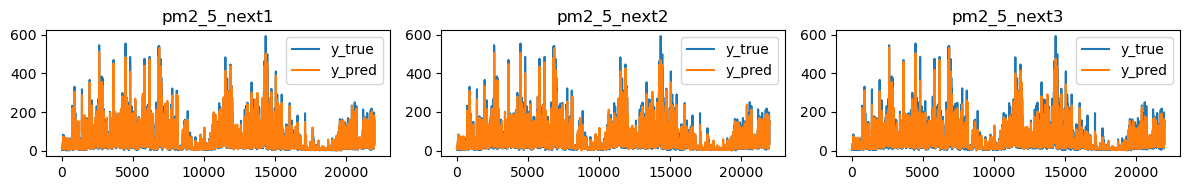

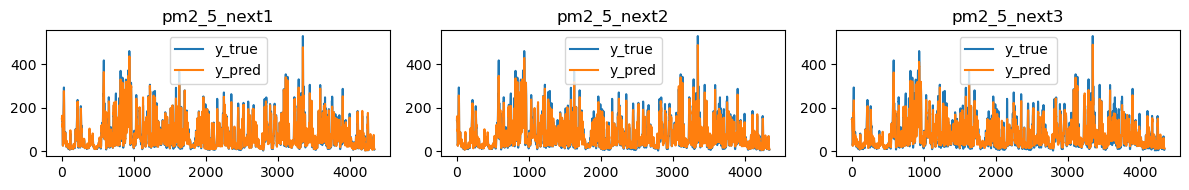

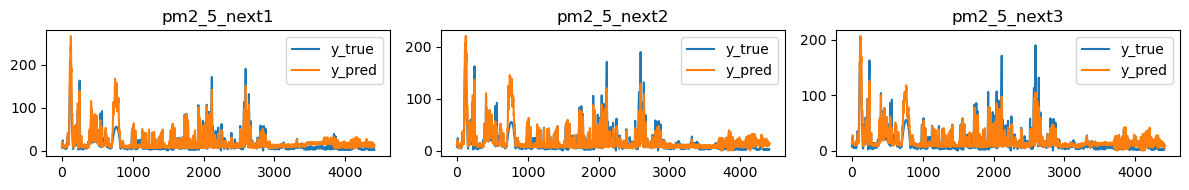

In [48]:
fig, axs = plt.subplots(1, 3, figsize=(12, 2))

for i, target in enumerate(target_col):
    axs[i].plot(y_train[target].reset_index(drop=True), label='y_true')
    axs[i].plot(y_pred_train_df[target], label='y_pred')
    axs[i].set_title(target)
    axs[i].legend()

plt.tight_layout()
plt.show()
plt.close(fig)

fig, axs = plt.subplots(1, 3, figsize=(12, 2))

for i, target in enumerate(target_col):
    axs[i].plot(y_val[target].reset_index(drop=True), label='y_true')
    axs[i].plot(y_pred_val_df[target], label='y_pred')
    axs[i].set_title(target)
    axs[i].legend()

plt.tight_layout()
plt.show()
plt.close(fig)

fig, axs = plt.subplots(1, 3, figsize=(12, 2))

for i, target in enumerate(target_col):
    axs[i].plot(y_test[target].reset_index(drop=True), label='y_true')
    axs[i].plot(y_pred_test_df[target], label='y_pred')
    axs[i].set_title(target)
    axs[i].legend()

plt.tight_layout()
plt.show()
plt.close(fig)